In [19]:
# ==========================================
# Cell 1: Imports and Directory Setup
# ==========================================
import os
import glob
import pickle
import numpy as np
from astropy.io import fits
from astropy.table import Table
from astropy.visualization import make_lupton_rgb
import matplotlib.pyplot as plt
from tqdm import tqdm
from lsst.daf.butler import Butler
from slsim.LsstSciencePipeline import lsst_science_pipeline

from utils import extract_lens_properties, robust_batch_lens_injection, patch_is_crowded, plot_injected_montage, plot_noise_std_histograms

import warnings
warnings.filterwarnings("ignore")

%load_ext autoreload
%autoreload 2

# Define and create output directories
img_dir = "../data_injected/lenses/images/"
table_dir = "../data_injected/lenses/"
os.makedirs(img_dir, exist_ok=True)
os.makedirs(table_dir, exist_ok=True)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
# ==========================================
# Cell 2: Load Lens Objects
# ==========================================
# Sorted so object order (and hence the Lens IDs assigned to them) is identical across runs
lens_files = sorted(glob.glob("../saved_objects/lensed_quasars_balanced_*.pkl"))

lensed_quasars_all = []
print(f"Found {len(lens_files)} lens files. Loading...")
for file in lens_files:
    with open(file, "rb") as f:
        lensed_quasars_all.extend(pickle.load(f))

print(f"Total lenses loaded: {len(lensed_quasars_all)}")
num_lenses = len(lensed_quasars_all)


Found 1 lens files. Loading...
Total lenses loaded: 50000


In [3]:
# ==========================================
# Cell 3: Extract Properties (reuse cached table if present)
# ==========================================
base_table_path = os.path.join(table_dir, "table_lensed_quasars_base.fits")

if os.path.exists(base_table_path):
    print(f"Base catalog already exists, loading from {base_table_path}")
    table_lensed_quasars = Table.read(base_table_path, format="fits")
else:
    print("Extracting physical properties into base catalog table...")
    table_lensed_quasars = extract_lens_properties(
        lensed_quasars_all, all_bands=['g', 'r', 'i', 'z', 'y'], max_num_images=5
    )
    table_lensed_quasars.write(base_table_path, format="fits", overwrite=True)
    print(f"Saved base catalog to {base_table_path}")


Extracting physical properties into base catalog table...


Extracting lens properties: 100%|██████████| 50000/50000 [2:23:38<00:00,  5.80it/s]  


Saved base catalog to ../data_injected/lenses/table_lensed_quasars_base.fits


In [4]:
# ==========================================
# Cell 4: Initialize Butler and Injection Parameters
# ==========================================
print("Initializing Butler...")
butler = Butler("dp02", collections="2.2i/runs/DP0.2")

band_list = ['g', 'r', 'i', 'z', 'y']
num_pix = 41
pixel_scale = 0.2
transform_matrix = np.array([[pixel_scale, 0], [0, pixel_scale]])

# Batch parameter to fetch new patches of sky incrementally
lenses_per_patch = 500


Initializing Butler...


In [5]:
# ==========================================
# Cell 5: Resume Check (skip lenses already injected on disk)
# ==========================================
def find_completed_ids(img_dir, band_list):
    """Return {obj_id: (ra, dec)} for objects that already have all bands saved on disk."""
    completed = {}
    suffix = f"_{band_list[0]}.fits"
    for fpath in glob.glob(os.path.join(img_dir, f"*{suffix}")):
        obj_id = os.path.basename(fpath)[: -len(suffix)]
        if all(os.path.exists(os.path.join(img_dir, f"{obj_id}_{b}.fits")) for b in band_list):
            with fits.open(fpath) as hdul:
                ra = hdul[0].header.get("RA_OBJ", np.nan)
                dec = hdul[0].header.get("DEC_OBJ", np.nan)
            completed[obj_id] = (ra, dec)
    return completed

completed = find_completed_ids(img_dir, band_list)
print(f"Found {len(completed)} lenses already injected on disk. Resuming from there...")

successful_indices = []
pending_indices = []
for i, obj_id in enumerate(table_lensed_quasars["Lens ID"]):
    if obj_id in completed:
        ra, dec = completed[obj_id]
        table_lensed_quasars[i]["RA"] = ra
        table_lensed_quasars[i]["Dec"] = dec
        successful_indices.append(i)
    else:
        pending_indices.append(i)

print(f"{len(pending_indices)} lenses remaining to inject.")


Found 0 lenses already injected on disk. Resuming from there...
50000 lenses remaining to inject.


In [6]:
# ==========================================
# Cell 6: Batch Injection and Rendering
# ==========================================
attempt_counts = {}
max_patch_attempts = 40  # safety valve for a lens that can never find a valid patch

print(f"Starting batch injection of {len(pending_indices)} remaining lenses into DP0 images...")

with tqdm(total=num_lenses, initial=len(successful_indices)) as pbar:
    while pending_indices:
        batch_indices = pending_indices[:lenses_per_patch]
        remaining_after_batch = pending_indices[lenses_per_patch:]
        current_lens_batch = [lensed_quasars_all[i] for i in batch_indices]

        # Random RA/Dec within the DP0.2 WFD footprint
        ra = np.random.uniform(55.0, 70.0)
        dec = np.random.uniform(-43.0, -30.0)

        try:
            coadd_list, coadd_nImage_list, _, variance_map_list = lsst_science_pipeline.get_dp0_images(
                butler=butler, ra=ra, dec=dec, band_list=band_list, coadd_injection=True
            )
            mag_zero_list = [2.5 * np.log10(coadd.getPhotoCalib().getInstFluxAtZeroMagnitude()) for coadd in coadd_list]
        except Exception as e:
            # Invalid/empty/out-of-bounds patch; try a new coordinate on the next loop
            continue

        # Cheap pre-check: skip whole patches too crowded to be worth a full batch attempt
        if patch_is_crowded(coadd_list, variance_map_list, band_list, pixel_scale, num_pix):
            continue

        # lens_ids=batch_indices: match results back to the table by row index,
        # NOT by lens.generate_id() - that string is built from a couple of
        # rounded physical parameters and is not guaranteed unique across a
        # large/"balanced" sample, so it can silently collide between objects.
        batch_results, batch_failures = robust_batch_lens_injection(
            lens_batch=current_lens_batch,
            lens_ids=batch_indices,
            num_pix=num_pix,
            coadd_list=coadd_list,
            coadd_nImage_list=coadd_nImage_list,
            mag_zero_list=mag_zero_list,
            variance_map_list=variance_map_list,
            transform_matrix=transform_matrix,
            band_list=band_list,
            coadd_year=1,
            max_retries=10,
            snr_threshold=5,
            verbose=False,
        )

        succeeded_indices = set()
        for sample in batch_results:
            idx = sample["row_id"]
            obj_id = table_lensed_quasars[idx]["Lens ID"]

            table_lensed_quasars[idx]["RA"] = sample["cutout_center"][0]
            table_lensed_quasars[idx]["Dec"] = sample["cutout_center"][1]

            # Save images; RA/Dec also stored in the header so progress survives a crash
            for band in band_list:
                hdr = fits.Header()
                hdr["RA_OBJ"] = sample["cutout_center"][0]
                hdr["DEC_OBJ"] = sample["cutout_center"][1]
                fits_path = os.path.join(img_dir, f"{obj_id}_{band}.fits")
                fits.writeto(fits_path, sample["injected_images"][band], header=hdr, overwrite=True)

            successful_indices.append(idx)
            succeeded_indices.add(idx)
            pbar.update(1)

        # Split failures: a real exception won't be fixed by trying elsewhere,
        # so drop those immediately and surface the error. Location-based
        # failures still get requeued for a fresh patch.
        still_pending = []
        for i in batch_indices:
            if i in succeeded_indices:
                continue
            reason = batch_failures.get(i, "unknown")
            obj_id_i = table_lensed_quasars[i]["Lens ID"]
            if reason.startswith("exception"):
                tqdm.write(f"Dropping {obj_id_i} (index {i}) permanently - {reason}")
                continue
            attempt_counts[i] = attempt_counts.get(i, 0) + 1
            if attempt_counts[i] >= max_patch_attempts:
                tqdm.write(f"Warning: giving up on {obj_id_i} (index {i}) after {max_patch_attempts} patch attempts ({reason}).")
                continue
            still_pending.append(i)

        tqdm.write(f"Patch: {len(succeeded_indices)}/{len(batch_indices)} injected, {len(still_pending)} requeued.")
        pending_indices = remaining_after_batch + still_pending

print(f"\nInjection complete! {len(successful_indices)}/{num_lenses} lenses successfully injected.")


Starting batch injection of 50000 remaining lenses into DP0 images...


  0%|          | 250/50000 [05:08<1:23:04,  9.98it/s]  

Patch: 250/250 injected, 0 requeued.


  1%|          | 500/50000 [10:21<1:20:32, 10.24it/s]  

Patch: 250/250 injected, 0 requeued.


  2%|▏         | 750/50000 [15:18<1:17:48, 10.55it/s]  

... (391 outputs left out)

100%|█████████▉| 49750/50000 [18:01:27<00:24, 10.41it/s]  

Patch: 250/250 injected, 0 requeued.


100%|██████████| 50000/50000 [18:07:10<00:00,  1.30s/it]  


Patch: 250/250 injected, 0 requeued.

Injection complete! 50000/50000 lenses successfully injected.


In [7]:
# ==========================================
# Cell 7: Save Filtered Catalog and Zip
# ==========================================
successful_indices = sorted(successful_indices)
table_lensed_quasars_final = table_lensed_quasars[successful_indices]

table_path = os.path.join(table_dir, "table_lensed_quasars_injected.fits")
table_lensed_quasars_final.write(table_path, format="fits", overwrite=True)
print(f"Saved injected catalog to {table_path}")

import shutil
shutil.make_archive(os.path.join(table_dir, "lensed_quasars_injected_images"), 'zip', img_dir)
print(f"✅ All images zipped to {os.path.join(table_dir, 'lensed_quasars_injected_images.zip')}")
zip_file_size = os.path.getsize(os.path.join(table_dir, "lensed_quasars_injected_images.zip")) / (1024 ** 3)
print(f"✅ Zip file size: {zip_file_size:.2f} GB")


Saved injected catalog to ../data_injected/lenses/table_lensed_quasars_injected.fits
✅ All images zipped to ../data_injected/lenses/lensed_quasars_injected_images.zip
✅ Zip file size: 3.09 GB


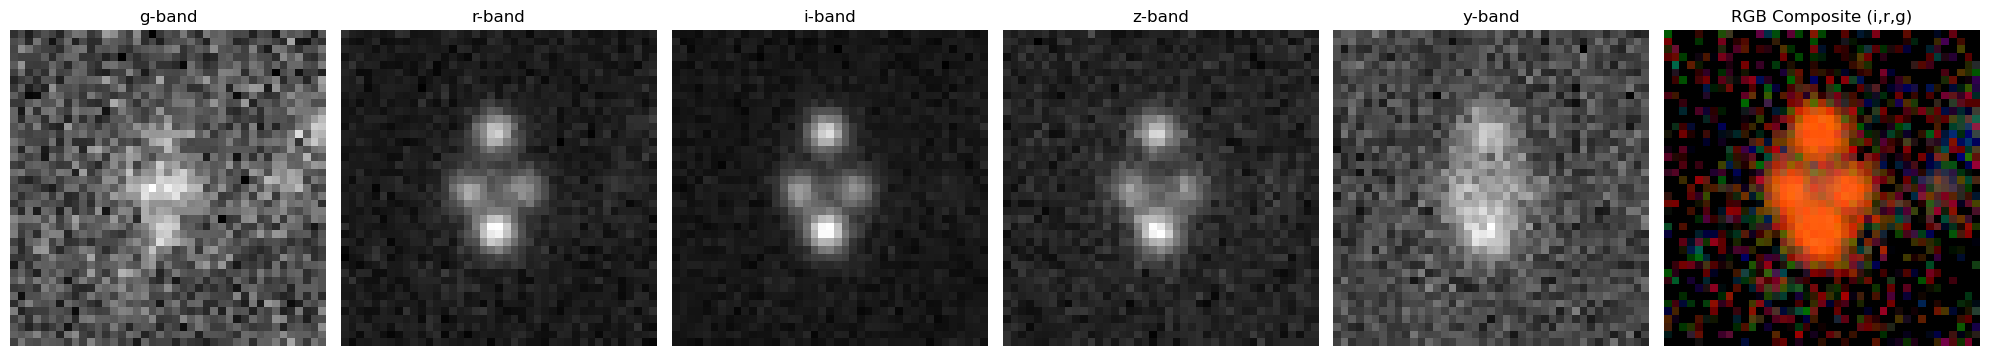

In [11]:
# ==========================================
# Cell 8: Verification - Load and Display a Saved Lens
# ==========================================
sample_id = table_lensed_quasars_final["Lens ID"][25010]

test_loaded_image = {}
for band in band_list:
    with fits.open(os.path.join(img_dir, f"{sample_id}_{band}.fits")) as hdul:
        test_loaded_image[band] = hdul[0].data

fig, axes = plt.subplots(1, 6, figsize=(20, 4))
for i, band in enumerate(band_list):
    axes[i].imshow(test_loaded_image[band], cmap='gray', origin='lower')
    axes[i].set_title(f"{band}-band")
    axes[i].axis('off')

rgb_image = make_lupton_rgb(test_loaded_image['i'], test_loaded_image['r'], test_loaded_image['g'], stretch=0.5)
axes[5].imshow(rgb_image, origin='lower')
axes[5].set_title("RGB Composite (i,r,g)")
axes[5].axis('off')
plt.tight_layout()
plt.show()


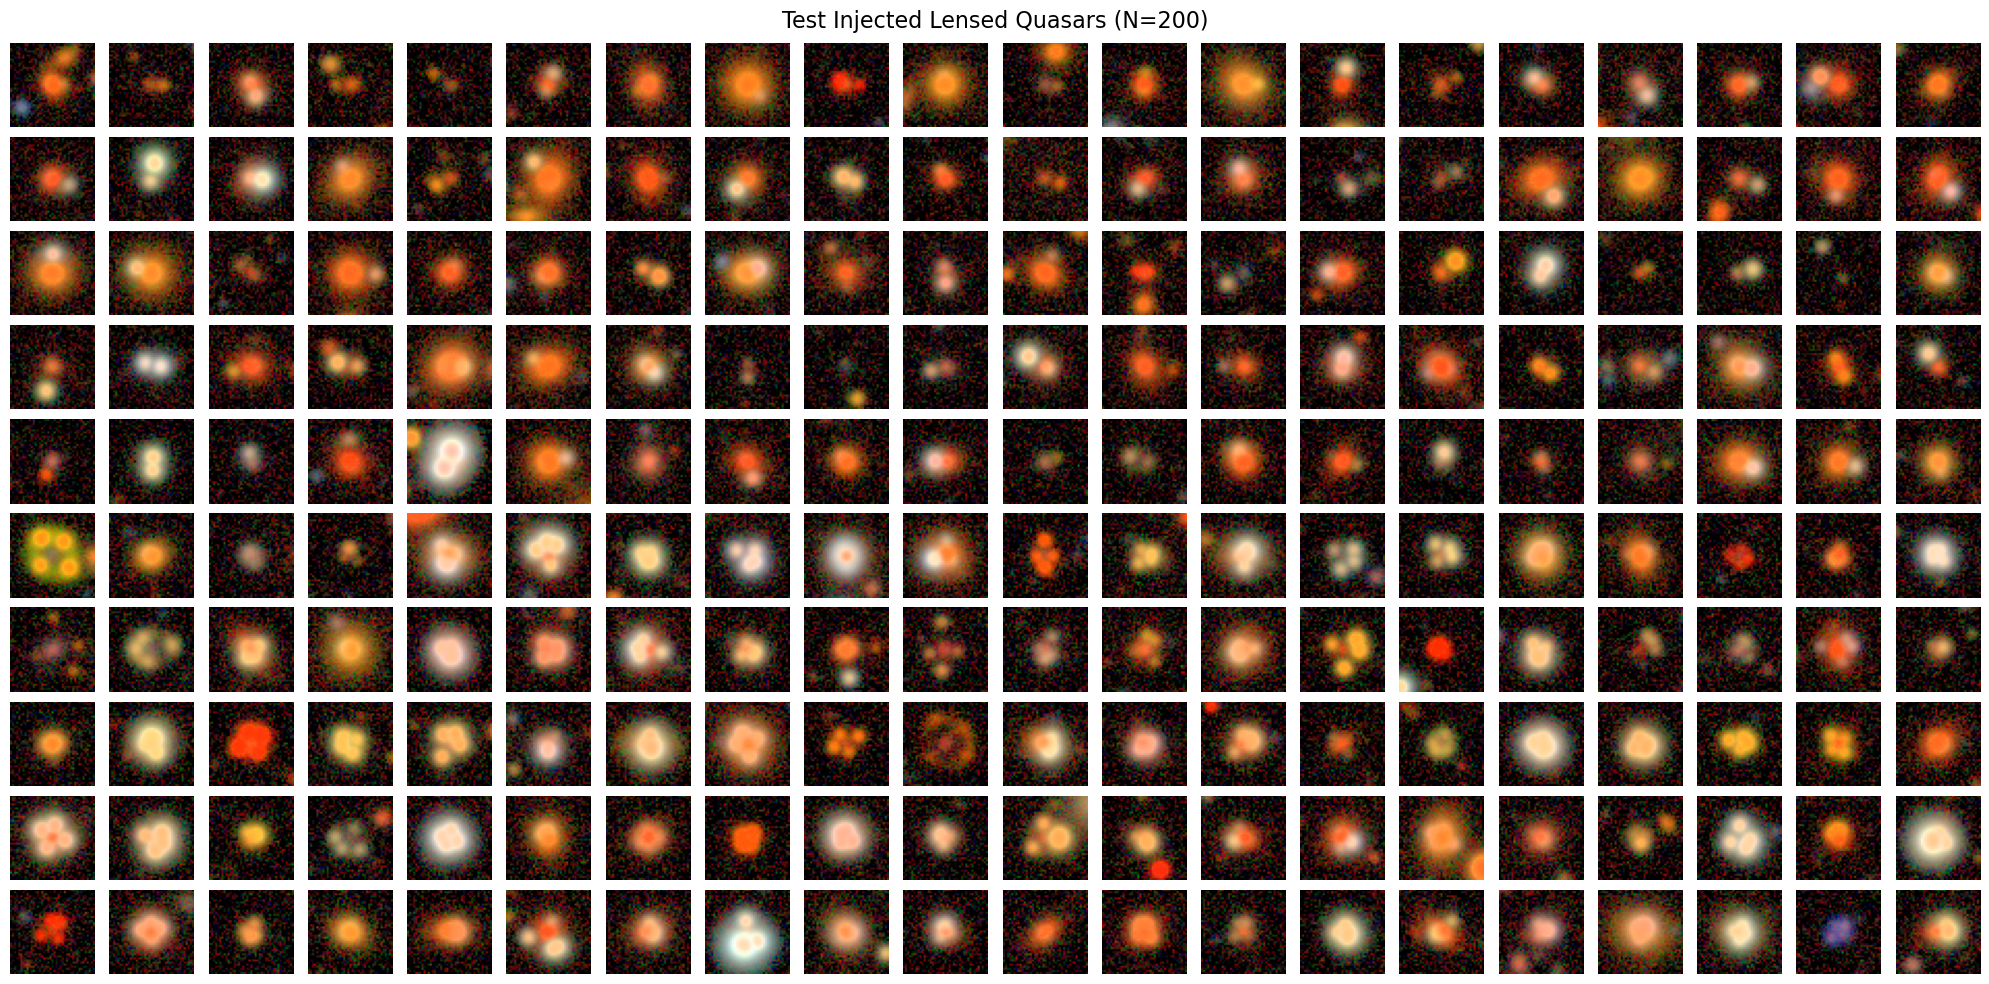

In [17]:
# ==========================================
# Cell 9: Montage - Visualize Injected Lenses
# ==========================================
test_ids = [table_lensed_quasars_final[i]["Lens ID"] for i in range(25000-100, 25100, 1)]

plot_injected_montage(
    test_ids,
    img_dir,
    band_list=band_list,
    rgb_bands=['i', 'r', 'g'],
    num_cols=20,
    plot_title=f"Test Injected Lensed Quasars (N={len(test_ids)})",
)
plt.show()


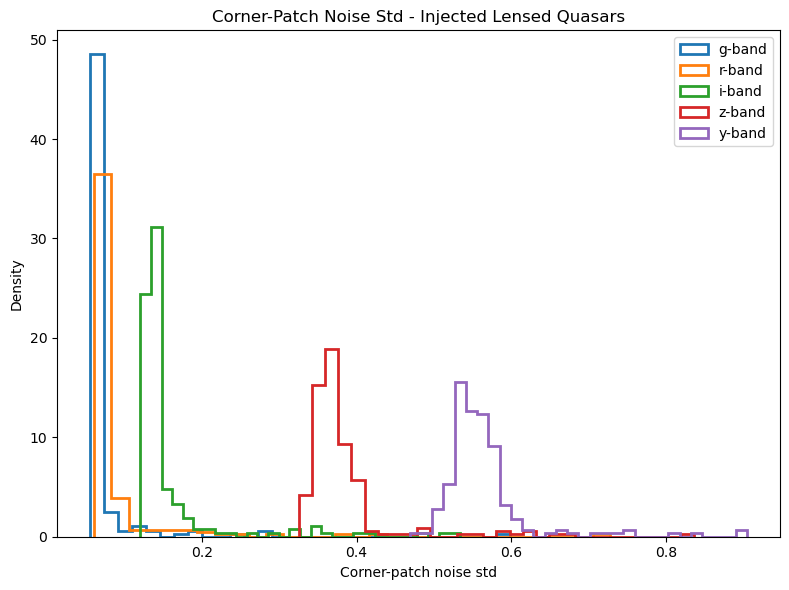

In [21]:
# ==========================================
# Cell 7: Noise Check - Corner-Patch Noise Std per Band
# ==========================================
plot_noise_std_histograms(
    test_ids,
    img_dir,
    band_list=band_list,
    corner_size=9,
    plot_title="Corner-Patch Noise Std - Injected Lensed Quasars",
)
plt.show()
